# Calibration de ResNet18 (ECE, diagramme de fiabilité, temperature scaling)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import softmax, log_softmax
from scipy.optimize import minimize_scalar

os.makedirs("../results/figures", exist_ok=True)

d = np.load("../results/logits_resnet18.npz")
val_logits,  val_y  = d["val_logits"],  d["val_y"]
test_logits, test_y = d["test_logits"], d["test_y"]
print("val :", val_logits.shape, "| test :", test_logits.shape)

val : (1120, 4) | test : (1600, 4)


## 1. Confiance et prédiction

Un softmax transforme les logits en probabilités. La **confiance** d'une image est la plus grande probabilité,
la **prédiction** est la classe qui la porte. `T` (température) divise les logits avant le softmax ; `T = 1` = modèle d'origine.

In [2]:
def conf_pred(logits, T=1.0):
    p = softmax(logits / T, axis=1)
    return p.max(axis=1), p.argmax(axis=1)

conf, pred = conf_pred(test_logits)
correct = (pred == test_y).astype(float)
print(f"Exactitude test : {correct.mean():.4f}")
print(f"Confiance moyenne test : {conf.mean():.4f}")

Exactitude test : 0.9431
Confiance moyenne test : 0.9753


## 2. Intervalles de confiance et ECE

On range les images par confiance (10 intervalles). Dans chaque intervalle on compare
la **confiance moyenne** à l'**exactitude réelle**. L'ECE est la moyenne de ces écarts, pondérée par la part d'images de l'intervalle :

$$\mathrm{ECE}=\sum_{m=1}^{M}\frac{|B_m|}{n}\,\big|\mathrm{acc}(B_m)-\mathrm{conf}(B_m)\big|$$

In [3]:
def calibration_bins(conf, correct, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() == 0:
            continue
        rows.append((lo, hi, int(m.sum()), conf[m].mean(), correct[m].mean()))
    return rows  # (borne basse, borne haute, effectif, confiance moyenne, exactitude)

def ece(conf, correct, n_bins=10):
    n = len(conf)
    return sum(cnt / n * abs(acc - c) for _, _, cnt, c, acc in calibration_bins(conf, correct, n_bins))

for lo, hi, cnt, c, acc in calibration_bins(conf, correct):
    print(f"[{lo:.1f}, {hi:.1f}]  n={cnt:5d}  confiance={c:.3f}  exactitude={acc:.3f}")
print(f"\nECE test (avant) = {ece(conf, correct):.4f}")

[0.3, 0.4]  n=    1  confiance=0.336  exactitude=1.000
[0.4, 0.5]  n=    8  confiance=0.473  exactitude=0.250
[0.5, 0.6]  n=   16  confiance=0.549  exactitude=0.500
[0.6, 0.7]  n=   29  confiance=0.647  exactitude=0.379
[0.7, 0.8]  n=   28  confiance=0.740  exactitude=0.464
[0.8, 0.9]  n=   21  confiance=0.854  exactitude=0.571
[0.9, 1.0]  n= 1497  confiance=0.995  exactitude=0.977

ECE test (avant) = 0.0330


## 3. Autres mesures : NLL et score de Brier

- **NLL** : pénalise fortement les erreurs commises avec une grande confiance.
- **Brier** : écart quadratique entre les probabilités et la bonne réponse (one-hot).

In [4]:
def nll(logits, y, T=1.0):
    return -log_softmax(logits / T, axis=1)[np.arange(len(y)), y].mean()

def brier(logits, y, T=1.0):
    p = softmax(logits / T, axis=1)
    onehot = np.eye(p.shape[1])[y]
    return ((p - onehot) ** 2).sum(axis=1).mean()

def report(name, logits, y, T=1.0, n_bins=10):
    conf, pred = conf_pred(logits, T)
    correct = (pred == y).astype(float)
    return {
        "jeu": name, "T": round(T, 3),
        "exactitude": correct.mean(), "confiance_moy": conf.mean(),
        "ECE": ece(conf, correct, n_bins),
        "NLL": nll(logits, y, T), "Brier": brier(logits, y, T),
    }

## 4. Temperature scaling

On cherche le seul nombre `T > 0` qui minimise la NLL de `softmax(logits / T)` sur la **validation**.
`T > 1` adoucit les probabilités (modèle trop sûr de lui), `T < 1` les durcit.
Comme `T` divise tous les logits de la même façon, **l'ordre des classes ne change pas** : les prédictions et l'exactitude restent identiques.

In [5]:
res = minimize_scalar(lambda T: nll(val_logits, val_y, T), bounds=(0.05, 10), method="bounded")
T_star = res.x
print(f"T* appris sur la validation = {T_star:.3f}")

T* appris sur la validation = 0.999


In [6]:
import pandas as pd

rows = [
    report("val  (avant)", val_logits,  val_y,  1.0),
    report("val  (après)", val_logits,  val_y,  T_star),
    report("test (avant)", test_logits, test_y, 1.0),
    report("test (après)", test_logits, test_y, T_star),
]
table = pd.DataFrame(rows).round(4)
table.to_csv("../results/calibration_resnet18.csv", index=False)
table

,jeu,T,exactitude,confiance_moy,ECE,NLL,Brier
0,val (avant),1.000,0.9857,0.9853,0.0055,0.0448,0.0209
1,val (après),0.999,0.9857,0.9853,0.0055,0.0448,0.0209
2,test (avant),1.000,0.9431,0.9753,0.0330,0.2926,0.0897
3,test (après),0.999,0.9431,0.9753,0.0330,0.2928,0.0897


## 5. Diagramme de fiabilité

Barres = exactitude réelle par intervalle ; diagonale = calibration parfaite.
Les barres **sous** la diagonale signalent un modèle trop confiant. L'histogramme du bas montre combien d'images sont dans chaque intervalle
(à lire avant de conclure : un intervalle avec 3 images ne prouve rien).

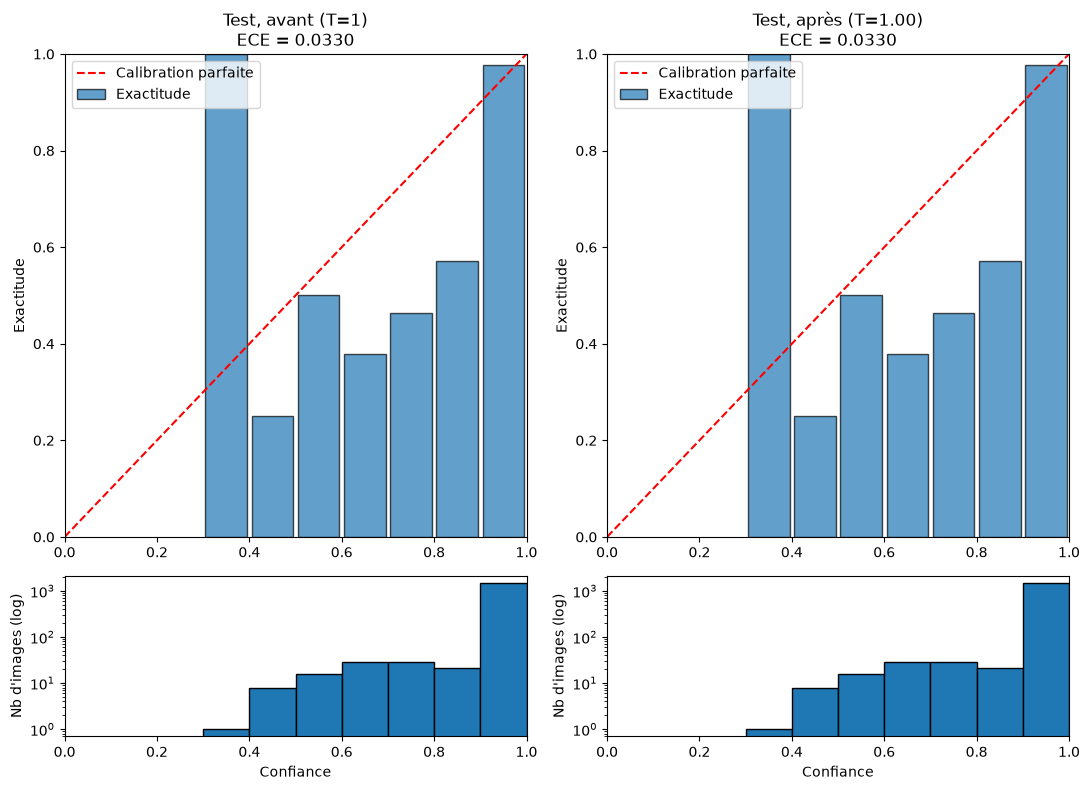

In [7]:
def plot_reliability(conf, correct, title, axes, n_bins=10):
    ax1, ax2 = axes
    rows = calibration_bins(conf, correct, n_bins)
    centers = [(lo + hi) / 2 for lo, hi, *_ in rows]
    accs = [r[4] for r in rows]
    ax1.bar(centers, accs, width=1 / n_bins * 0.9, edgecolor="black", alpha=0.7, label="Exactitude")
    ax1.plot([0, 1], [0, 1], "r--", label="Calibration parfaite")
    ax1.set_xlim(0, 1); ax1.set_ylim(0, 1)
    ax1.set_ylabel("Exactitude"); ax1.set_title(f"{title}\nECE = {ece(conf, correct, n_bins):.4f}")
    ax1.legend(loc="upper left")
    ax2.hist(conf, bins=np.linspace(0, 1, n_bins + 1), edgecolor="black")
    ax2.set_xlim(0, 1); ax2.set_yscale("log")
    ax2.set_xlabel("Confiance"); ax2.set_ylabel("Nb d'images (log)")

fig, axes = plt.subplots(2, 2, figsize=(11, 8), gridspec_kw={"height_ratios": [3, 1]})
for col, (T, label) in enumerate([(1.0, "Test, avant (T=1)"), (T_star, f"Test, après (T={T_star:.2f})")]):
    c, p = conf_pred(test_logits, T)
    plot_reliability(c, (p == test_y).astype(float), label, (axes[0, col], axes[1, col]))
plt.tight_layout()
plt.savefig("../results/figures/reliability_resnet18.png", dpi=150)
plt.show()